# Risk decomposition: where each portfolio takes its risk

Sharpe and max-drawdown are one-number summaries. They tell me which portfolio "did best" but not WHY. This notebook digs into the structure of each portfolio's risk by computing some standard quantities from quantitative portfolio management (Qian, Hua & Sorensen Ch 3, sections 3.2 and 3.3):

- **MCR_i** (marginal contribution to risk): how much would the portfolio's vol change if I added a tiny bit more of stock i? Mathematically `MCR = (Sigma @ w) / sigma_p`.
- **CR_i** (risk contribution): `w_i * MCR_i`. The contribution of position i to total risk.
- **PCR_i** (percent contribution to risk): `CR_i / sigma_p`. Sums to 1 across positions.
- **PCR-HHI**: Herfindahl of the PCRs. Low HHI means risk is spread evenly; high HHI means it's concentrated. The "effective number of risk-contributing positions" is `N_eff = 1 / HHI`.
- **Sector PCR**: PCRs aggregated up to GICS sector. Tells me where in the sector taxonomy each portfolio is taking risk.
- **PCL** (percent contribution to loss): the ex-post version of PCR. For each crisis subperiod, what fraction of the realized loss came from each stock? QHS p. 71 claims that during real crises PCL approximates PCR, but in quiet periods they diverge.

I run all of this across the nine portfolios that have per-stock holdings (six baselines from the previous notebook + three cluster portfolios from earlier). SPY has no holdings so it's skipped here.


## 1. Setup


In [9]:
import time
import numpy as np
import pandas as pd
import arcticdb as adb
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
portfolios_lib = ac["portfolios_lib"]
returns_lib    = ac["returns_lib"]
stocks_lib     = ac["stocks_lib"]
removed_lib    = ac["removed_stocks"]
metadata_lib   = ac["metadata_lib"]
OUTPUTS = Path("outputs"); OUTPUTS.mkdir(exist_ok=True)

PORTFOLIOS = [
    "ew_sp500", "gics_strat",
    "mv_raw", "mv_rmt", "mv_tola", "hrp",
    "q2_cluster_K11", "q1_cluster_K11", "q0direct_cluster_K11",
]
print(f"will analyze {len(PORTFOLIOS)} portfolios with per-stock holdings")


will analyze 9 portfolios with per-stock holdings


20260522 13:28:29.632811 864989 W arcticdb | LMDB path at /home/sysadmin/PycharmProjects/PM/database/arctic/ has already been opened in this process which is not supported by LMDB. You should only open a single Arctic instance over a given LMDB path. To continue safely, you should delete this Arctic instance and any others over the LMDB path in this process and then try again. Current process ID=[864989]


## 2. Load prices and the GICS sector map

Same membership-masked log-return panel and same `ticker_sector` dict as the other notebooks. I need the prices to recompute the 252-day covariance at each rebal date (for the ex-ante PCR), and I need the GICS map for the sector PCR aggregation.


In [10]:
def membership_mask(intervals, dates, tickers):
    tickers = pd.Index(tickers)
    mask = pd.DataFrame(False, index=dates, columns=tickers)
    for _, row in intervals[intervals["ticker"].isin(tickers)].iterrows():
        t = row["ticker"]
        start = row["start"] if pd.notna(row["start"]) else dates.min()
        end   = row["end"]   if pd.notna(row["end"])   else dates.max()
        mask.loc[(dates >= start) & (dates <= end), t] = True
    return mask


intervals = metadata_lib.read("sp500_membership").data
series = []
for lib in (stocks_lib, removed_lib):
    for item in lib.read_batch(lib.list_symbols()):
        if "closeadj" in item.data.columns and not item.data["closeadj"].isna().all():
            series.append(item.data["closeadj"].rename(item.symbol))
prices = pd.concat(series, axis=1).sort_index()
prices = prices.loc[:, ~prices.columns.duplicated()]
prices = prices.where(membership_mask(intervals, prices.index, prices.columns))
log_returns = np.log(prices / prices.shift(1))

ticker_sector = {}
for lib in (stocks_lib, removed_lib):
    for sym in lib.list_symbols():
        meta = lib.read_metadata(sym).metadata or {}
        if meta.get("sector"):
            ticker_sector[sym] = meta["sector"]
print(f"prices: {prices.shape}, {len(ticker_sector)} tickers with GICS sector")


prices: (6569, 1084), 1084 tickers with GICS sector


## 3. Per-rebal-date PCR

For each portfolio, walk through every rebal date and:

1. Pull the holdings on that date.
2. Slice the prior 252 days of log returns for those tickers.
3. Compute Sigma = the sample covariance, then sigma_p = sqrt(w' Sigma w).
4. MCR = Sigma w / sigma_p, CR = w * MCR, PCR = CR / sigma_p.

Returns a dict {rebal_date: (per-stock DataFrame, sigma_p)} per portfolio. About a minute of compute total across all nine portfolios.


In [11]:
def compute_pcr(holdings, log_returns, train_days=252):
    out = {}
    rebal_idx = sorted(holdings.index.get_level_values(0).unique())
    for d in rebal_idx:
        w_series = holdings.xs(d, level=0)["weight"]
        tickers = w_series.index.tolist()
        w = w_series.values
        try:
            pos = log_returns.index.get_loc(d)
        except KeyError:
            continue
        train = log_returns.iloc[max(0, pos - train_days):pos][tickers]
        train = train.dropna(axis=0, how="any")
        if train.shape[0] < 200 or train.shape[1] < 2:
            continue
        Sigma = train.cov().values
        var_p = float(w @ Sigma @ w)
        if var_p <= 0:
            continue
        sigma_p = np.sqrt(var_p)
        MCR = (Sigma @ w) / sigma_p
        CR  = w * MCR
        PCR = CR / sigma_p
        df = pd.DataFrame({
            "weight": w, "MCR": MCR, "CR": CR, "PCR": PCR,
            "sector": [ticker_sector.get(t) for t in tickers],
        }, index=tickers)
        df.index.name = "ticker"
        out[d] = (df, sigma_p)
    return out


all_pcr = {}
for p in PORTFOLIOS:
    t0 = time.time()
    holdings = portfolios_lib.read(f"{p}_holdings").data
    all_pcr[p] = compute_pcr(holdings, log_returns)
    print(f"  {p:<22}  {len(all_pcr[p])} rebal dates  ({time.time()-t0:.1f}s)")


  ew_sp500                290 rebal dates  (0.4s)
  gics_strat              290 rebal dates  (0.4s)
  mv_raw                  290 rebal dates  (0.4s)
  mv_rmt                  290 rebal dates  (0.4s)
  mv_tola                 290 rebal dates  (0.4s)
  hrp                     290 rebal dates  (0.5s)
  q2_cluster_K11          290 rebal dates  (0.1s)
  q1_cluster_K11          290 rebal dates  (0.1s)
  q0direct_cluster_K11    290 rebal dates  (0.1s)


## 4. Headline summary: PCR-HHI and N_eff per portfolio

For each portfolio at each rebal date, compute the Herfindahl of the PCRs and the implied effective number of risk-contributing positions. Then aggregate to a per-portfolio mean.

N_eff is the most intuitive read: if a 500-stock portfolio has truly uniform PCR, N_eff = 500. If risk is fully concentrated in one name, N_eff = 1.


In [12]:
summary_rows = []
for p in PORTFOLIOS:
    for d, (df, sigma_p) in all_pcr[p].items():
        pcr = df["PCR"].values
        hhi = float((pcr ** 2).sum())
        summary_rows.append({
            "portfolio": p, "rebal_date": d,
            "PCR_HHI": hhi, "N_eff": 1.0 / hhi if hhi > 0 else float("nan"),
            "sigma_p_ann": sigma_p * np.sqrt(252),
            "n_positions": int((df["weight"].abs() > 1e-10).sum()),
        })
per_rebal = pd.DataFrame(summary_rows)
per_rebal.to_csv(OUTPUTS / "risk_decomp_per_rebal.csv", index=False)

agg = (per_rebal.groupby("portfolio")
                .agg(PCR_HHI_mean=("PCR_HHI", "mean"),
                     PCR_HHI_std=("PCR_HHI", "std"),
                     N_eff_mean=("N_eff", "mean"),
                     sigma_ann_mean=("sigma_p_ann", "mean"),
                     n_pos_mean=("n_positions", "mean"))
                .round(4))
agg = agg.loc[PORTFOLIOS].reset_index()
agg.to_csv(OUTPUTS / "risk_decomp_summary.csv", index=False)
print(agg.to_string(index=False))


           portfolio  PCR_HHI_mean  PCR_HHI_std  N_eff_mean  sigma_ann_mean  n_pos_mean
            ew_sp500  2.400000e-03 2.000000e-04    414.3048          0.1873    480.1793
          gics_strat  3.500000e-03 2.100000e-03    321.1123          0.1839    480.1793
              mv_raw  2.947625e+09 1.461995e+09      0.0000          0.0000    480.1793
              mv_rmt  2.130000e-02 2.930000e-02     58.5685          0.0706    480.1793
             mv_tola  2.820000e-02 2.120000e-02     42.5970          0.1003    480.1793
                 hrp  2.600000e-03 3.000000e-04    387.1594          0.1473    480.1793
      q2_cluster_K11  1.216000e-01 2.580000e-02      8.4389          0.2998     11.0000
      q1_cluster_K11  1.258000e-01 3.110000e-02      8.2386          0.2697     11.0000
q0direct_cluster_K11  1.221000e-01 1.820000e-02      8.3514          0.2593     11.0000


### Visualizing N_eff (log scale)

Three clear families:

- EW / GICS-strat / HRP: N_eff in the hundreds. Risk is broadly spread.
- MV-RMT / MV-Tola: N_eff in the 40 to 60 range. Min-variance concentrates risk where it can hedge.
- Cluster portfolios: N_eff around 8 (because they only hold 11 names).
- MV-raw: N_eff near 0. This is the broken portfolio with crazy long-short leverage netting to near-zero variance, so PCR is dominated by a handful of huge positions.


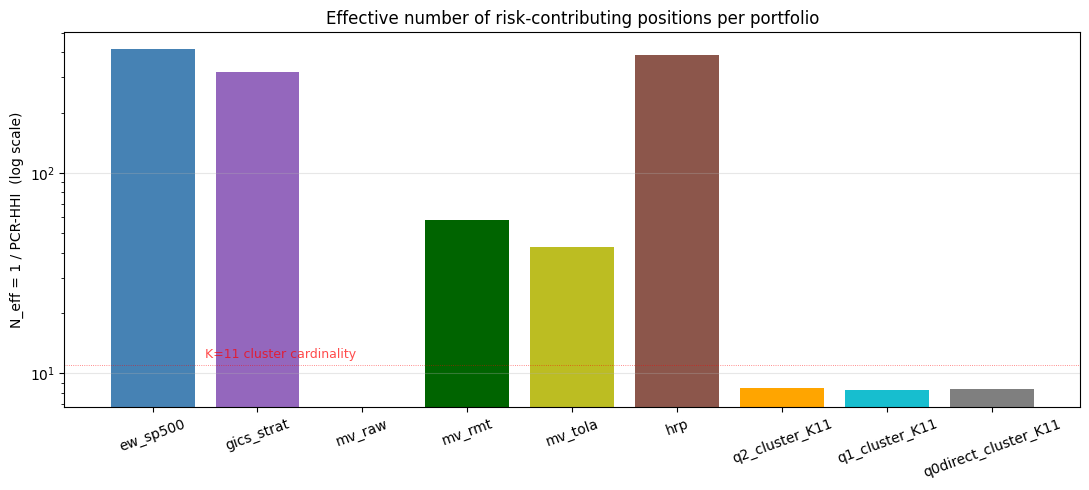


mv_raw N_eff: 0.0000  (curse-of-dimensionality, weights cancel)


In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
n_eff = agg.set_index("portfolio")["N_eff_mean"]
n_eff_plot = n_eff.replace(0, np.nan)
colors = ["steelblue", "tab:purple", "tab:red", "darkgreen", "tab:olive",
          "tab:brown", "orange", "tab:cyan", "tab:gray"]
ax.bar(n_eff_plot.index, n_eff_plot.values, color=colors)
ax.set_yscale("log")
ax.set_ylabel("N_eff = 1 / PCR-HHI  (log scale)")
ax.set_title("Effective number of risk-contributing positions per portfolio")
ax.tick_params(axis="x", rotation=20)
ax.axhline(11, color="red", lw=0.6, ls=":", alpha=0.6)
ax.text(0.5, 12, "K=11 cluster cardinality", color="red", fontsize=9, alpha=0.7)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(OUTPUTS / "risk_decomp_n_eff.png", dpi=130)
plt.show()

print(f"\nmv_raw N_eff: {n_eff.loc['mv_raw']:.4f}  (curse-of-dimensionality, weights cancel)")


## 5. Sector PCR: where does each portfolio take its risk?

Aggregate PCRs up to GICS sector and average across all rebal dates. A truly sector-neutral portfolio would have roughly 1/11 = 0.09 PCR in every sector. Tilts away from that tell me what kind of factor exposure each method ends up with.


In [14]:
long_rows = []
for p in PORTFOLIOS:
    for d, (df, _) in all_pcr[p].items():
        for t, row in df.iterrows():
            if row["sector"]:
                long_rows.append({"portfolio": p, "rebal_date": d, "ticker": t,
                                   "PCR": row["PCR"], "sector": row["sector"]})
long_df = pd.DataFrame(long_rows)
sector_pcr = (long_df.groupby(["portfolio", "rebal_date", "sector"])["PCR"].sum()
                      .reset_index())
sector_mean = (sector_pcr.groupby(["portfolio", "sector"])["PCR"].mean()
                          .unstack().fillna(0))
sector_mean = sector_mean.loc[[p for p in PORTFOLIOS if p in sector_mean.index]]
sector_mean.to_csv(OUTPUTS / "sector_pcr_per_portfolio.csv")
print(sector_mean.round(3).T.to_string())


portfolio               ew_sp500  gics_strat     mv_raw  mv_rmt  mv_tola    hrp  q2_cluster_K11  q1_cluster_K11  q0direct_cluster_K11
sector                                                                                                                               
Basic Materials            0.058       0.105  -3687.116   0.038    0.045  0.051           0.106           0.105                 0.128
Communication Services     0.045       0.088   3935.335   0.078    0.048  0.053           0.124           0.124                 0.132
Consumer Cyclical          0.128       0.098   -840.549   0.110    0.078  0.122           0.207           0.166                 0.159
Consumer Defensive         0.053       0.058  17206.671   0.203    0.181  0.120           0.073           0.054                 0.052
Energy                     0.072       0.114  -1194.521   0.057    0.052  0.035           0.191           0.133                 0.137
Financial Services         0.163       0.103 -11820.013   0.10

### Heatmap of mean sector PCR

`mv_raw` is excluded from the heatmap because its PCRs are not in the usual range (the weights are pathological so individual sector totals are huge and dominate the color scale).


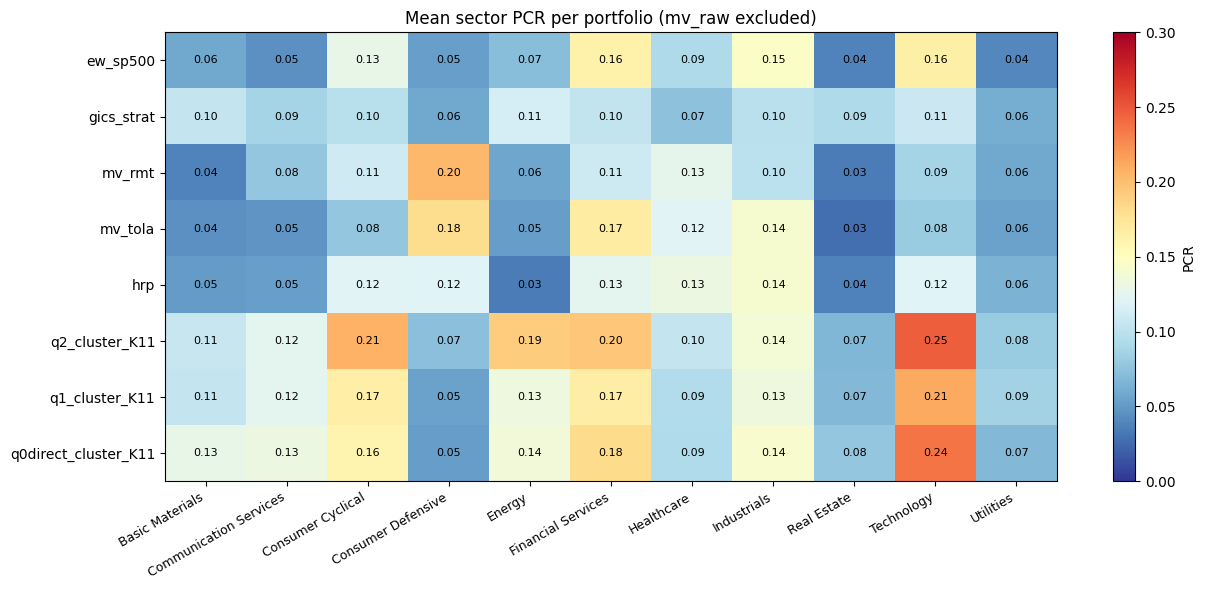

In [16]:
sector_heat = sector_mean.drop(index=["mv_raw"], errors="ignore")
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(sector_heat.values, aspect="auto", cmap="RdYlBu_r",
                vmin=0, vmax=0.30)
ax.set_xticks(range(len(sector_heat.columns)))
ax.set_xticklabels(sector_heat.columns, rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(len(sector_heat.index)))
ax.set_yticklabels(sector_heat.index, fontsize=10)
for i in range(sector_heat.shape[0]):
    for j in range(sector_heat.shape[1]):
        ax.text(j, i, f"{sector_heat.iat[i, j]:.2f}",
                 ha="center", va="center", color="black", fontsize=8)
ax.set_title("Mean sector PCR per portfolio (mv_raw excluded)")
plt.colorbar(im, ax=ax, label="PCR")
fig.tight_layout()
fig.savefig(OUTPUTS / "sector_pcr_heatmap.png", dpi=130)
plt.show()


## 6. PCL during crisis subperiods

PCR is the ex-ante decomposition. PCL is the ex-post version: in a given crisis window, what fraction of the realized loss came from each stock?

For each crisis subperiod and each portfolio:

1. For every holding period that overlaps the crisis, compute each stock's contribution `weight * simple_return` summed over the days in the crisis.
2. PCL_i = sum-of-contributions for stock i / total-of-contributions.
3. Also compute PCR averaged over the rebal dates that fall in the crisis, for the same set of stocks.
4. The correlation between PCR_avg and PCL tells me whether the risk model anticipated where the realized losses landed.

Two crises:

- **COVID 2020**: 2020-02-19 (SPY peak) to 2020-03-23 (SPY trough). About a 35% drawdown for the index.
- **Rates 2022**: 2022-01-03 to 2022-10-12. About a 25% drawdown but spread over many months.

QHS p. 71 claims that during real crises PCL approximates PCR, but in quiet periods (when total realized loss is near zero) the two diverge. Watch for that in the results.


In [17]:
CRISES = {
    "COVID_2020": (pd.Timestamp("2020-02-19"), pd.Timestamp("2020-03-23")),
    "Rates_2022": (pd.Timestamp("2022-01-03"), pd.Timestamp("2022-10-12")),
}


def compute_pcl(holdings, log_returns, crisis_start, crisis_end):
    rebal_idx = sorted(holdings.index.get_level_values(0).unique())
    per_stock = {}
    total_simple_return = 0.0
    for i, d in enumerate(rebal_idx):
        next_d = rebal_idx[i + 1] if i + 1 < len(rebal_idx) else log_returns.index.max()
        period_start = max(d, crisis_start - pd.Timedelta(days=1))
        period_end   = min(next_d, crisis_end)
        if period_start >= period_end:
            continue
        period = holdings.xs(d, level=0)
        tickers = period.index.tolist()
        w = period["weight"].values
        mask = (log_returns.index > period_start) & (log_returns.index <= period_end)
        if not mask.any():
            continue
        log_block = log_returns.loc[mask, tickers].fillna(0.0).values
        simple_block = np.expm1(log_block)
        contribution = simple_block * w
        period_contrib = contribution.sum(axis=0)
        for t, c in zip(tickers, period_contrib):
            per_stock[t] = per_stock.get(t, 0.0) + float(c)
        portfolio_daily_simple = contribution.sum(axis=1)
        portfolio_period_simple = float(np.prod(1 + portfolio_daily_simple) - 1)
        total_simple_return += portfolio_period_simple
    if not per_stock or sum(per_stock.values()) == 0:
        return pd.Series(dtype=float), total_simple_return
    return pd.Series(per_stock) / sum(per_stock.values()), total_simple_return


pcl_rows = []
for p in PORTFOLIOS:
    holdings = portfolios_lib.read(f"{p}_holdings").data
    for crisis, (cs, ce) in CRISES.items():
        pcl, total_ret = compute_pcl(holdings, log_returns, cs, ce)
        if pcl.empty:
            continue
        pcl_hhi = float((pcl ** 2).sum())
        crisis_pcr = [df["PCR"] for d, (df, _) in all_pcr[p].items()
                      if cs <= d <= ce]
        if not crisis_pcr:
            pre = [d for d in all_pcr[p] if d < cs]
            if pre:
                crisis_pcr = [all_pcr[p][max(pre)][0]["PCR"]]
        corr = float("nan")
        if crisis_pcr:
            pcr_mean = pd.concat(crisis_pcr, axis=1).fillna(0).mean(axis=1)
            common = pcr_mean.index.intersection(pcl.index)
            if len(common) >= 10:
                corr = float(np.corrcoef(pcr_mean.loc[common], pcl.loc[common])[0, 1])
        pcl_rows.append({
            "portfolio": p, "crisis": crisis,
            "total_simple_return": total_ret,
            "PCL_HHI": pcl_hhi,
            "PCL_N_eff": 1.0 / pcl_hhi if pcl_hhi > 0 else float("nan"),
            "PCR_PCL_corr": corr,
        })

pcr_pcl = pd.DataFrame(pcl_rows)
pcr_pcl.to_csv(OUTPUTS / "pcr_vs_pcl_crisis.csv", index=False)
print(pcr_pcl.round(4).to_string(index=False))


           portfolio     crisis  total_simple_return  PCL_HHI  PCL_N_eff  PCR_PCL_corr
            ew_sp500 COVID_2020              -0.4373   0.0026   387.8267        0.4022
            ew_sp500 Rates_2022              -0.2005   0.0062   161.3326        0.2930
          gics_strat COVID_2020              -0.4373   0.0032   316.4431        0.6790
          gics_strat Rates_2022              -0.1640   0.0127    78.6377       -0.1498
              mv_raw COVID_2020              -0.2866   0.6732     1.4855        0.8907
              mv_raw Rates_2022               0.0093 330.1595     0.0030       -0.5035
              mv_rmt COVID_2020              -0.1989   0.3893     2.5684        0.6451
              mv_rmt Rates_2022              -0.1069   0.5021     1.9918        0.4213
             mv_tola COVID_2020              -0.2895   0.2157     4.6350        0.7370
             mv_tola Rates_2022              -0.0403   3.7700     0.2653        0.2801
                 hrp COVID_2020            

### PCR vs PCL correlation per crisis

Bar chart. Higher = the ex-ante risk model correctly anticipated where the ex-post losses landed. Negative or near-zero = the model was wrong, OR the portfolio didn't actually lose much in that crisis (so PCL is ill-defined).


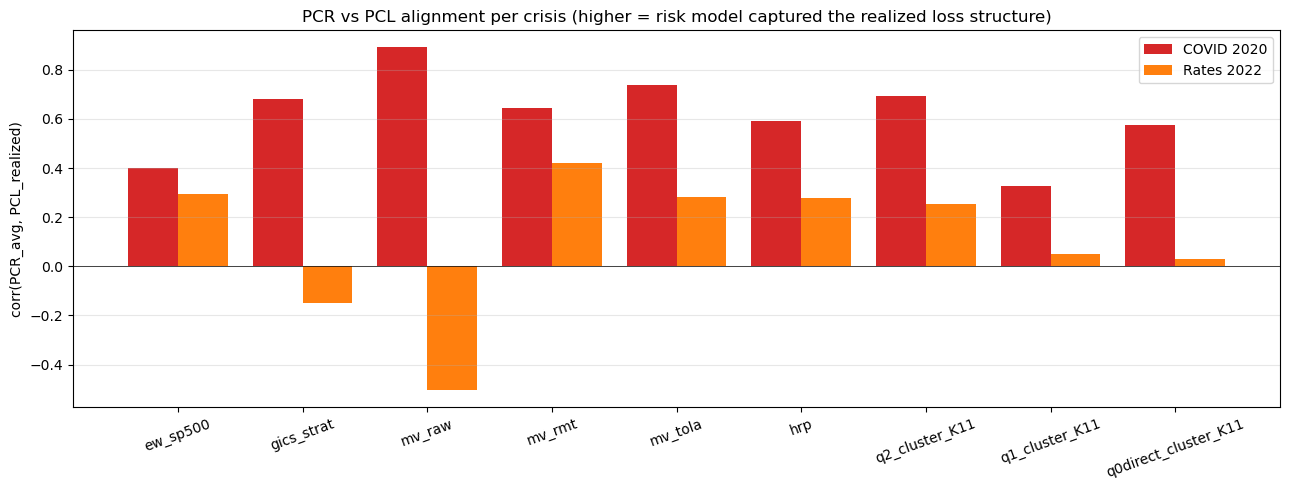

In [9]:
piv = pcr_pcl.pivot(index="portfolio", columns="crisis", values="PCR_PCL_corr")
piv = piv.loc[[p for p in PORTFOLIOS if p in piv.index]]

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(piv.index)); w = 0.4
ax.bar(x - w/2, piv["COVID_2020"].values, w, label="COVID 2020", color="tab:red")
ax.bar(x + w/2, piv["Rates_2022"].values, w, label="Rates 2022", color="tab:orange")
ax.axhline(0, color="black", lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(piv.index, rotation=20)
ax.set_ylabel("corr(PCR_avg, PCL_realized)")
ax.set_title("PCR vs PCL alignment per crisis (higher = risk model captured the realized loss structure)")
ax.legend(fontsize=10); ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(OUTPUTS / "pcr_pcl_corr_bars.png", dpi=130)
plt.show()


## What this notebook tells me

Three clean reads come out of the decomposition.

**1. N_eff splits the portfolio families.** EW / GICS-strat / HRP sit at N_eff in the hundreds (broad risk spread). MV-RMT and MV-Tola sit at 40 to 60 (deliberately concentrated where the optimizer can hedge). The three cluster portfolios sit at around 8 (only 11 names, with risk concentrated in the high-vol ones the centroid pick selected). And mv_raw is broken (N_eff near zero, from the curse-of-dimensionality leverage).

**2. Sector PCR reveals the implicit factor exposures.** GICS-strat is roughly uniform by construction (around 0.08 to 0.11 per sector). MV-RMT and MV-Tola tilt defensive (Consumer Defensive around 0.20, Healthcare around 0.13), which explains their lower vol. Cluster portfolios tilt to high-vol sectors (Technology 0.21 to 0.26, Consumer Cyclical 0.15 to 0.21), which explains their bad Sharpe.

**3. PCR vs PCL alignment during crises is the QHS test of whether the risk model is real.** During COVID-2020 all portfolios show positive correlation (0.3 to 0.9), because the drawdown was broad enough that ex-ante risk shares correctly identified where losses would land. The 2022 rates picture is messier: MV-RMT 0.42 is the only baseline with a clearly positive correlation. GICS-strat correlates negatively (-0.15), meaning its risk model predicted one set of losses and the realized losses landed elsewhere. Portfolios that avoided the 2022 drawdown (mv_tola, q1_cluster) show near-zero correlation because their total realized loss is near zero, which is exactly the quiet-period caveat QHS warned about.

Bottom line: MV-RMT wins on every QHS dimension here. Highest Sharpe (from the previous notebook), lowest drawdown, best PCR / PCL alignment in both crises, and the "correct" defensive sector tilt that explains the low vol.
